# Assignment 2: Convolution Networks for Cats and Dogs

**Steve Lambert | BA 64061 Advanced Machine Learning**

This notebook compares a CNN trained from scratch with a pretrained VGG16 network at three training sample sizes. The same 500 validation images and 500 test images are used for all experiments.

## Summary

The scratch CNN improved substantially as the training sample increased. Peak validation accuracy rose from **64.0%** with 1,000 images to **91.4%** with 20,000 images. VGG16 reached **97.0%** with only 1,000 images and remained near **98%** at the larger sample sizes. This shows that pretrained features are especially valuable when labeled data is limited.

## 1. Setup

In [1]:
from pathlib import Path
import json, random, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 64061
IMAGE_SIZE = (150, 150)
BATCH_SIZE = 64
TRAIN_SIZES = [1000, 5000, 20000]

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Load and split the data

I used the full 25,000-image collection. The training samples were balanced and nested. The validation and test sets were fixed across every experiment.

In [2]:
# The public repository contains the full 25,000-image dataset.
DATA_REPO = Path("dog-cat-full-dataset")
if not DATA_REPO.exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/ahatamiz/dog-cat-full-dataset.git",
        str(DATA_REPO)
    ], check=True)

DATA_ROOT = DATA_REPO / "data"

def collect_images():
    records = []
    for label_name, label in [("cats", 0), ("dogs", 1)]:
        for path in sorted(DATA_ROOT.glob(f"**/{label_name}/*.jpg")):
            records.append((str(path), label))
    return records

def make_splits(records):
    rng = np.random.default_rng(SEED)
    by_class = {0: [], 1: []}
    for path, label in records:
        by_class[label].append(path)
    for label in by_class:
        rng.shuffle(by_class[label])

    validation, test = [], []
    class_train = {}
    for label in [0, 1]:
        paths = by_class[label]
        validation += [(p, label) for p in paths[:250]]
        test += [(p, label) for p in paths[250:500]]
        class_train[label] = paths[500:10500]

    full_order = []
    pair_rng = np.random.default_rng(SEED + 99)
    for cat_path, dog_path in zip(class_train[0], class_train[1]):
        pair = [(cat_path, 0), (dog_path, 1)]
        pair_rng.shuffle(pair)
        full_order.extend(pair)

    train_sets = {n: full_order[:n] for n in TRAIN_SIZES}
    return train_sets, validation, test

records = collect_images()
train_sets, validation_rows, test_rows = make_splits(records)
print(f"Images found: {len(records):,}")
print("Training sizes:", [len(train_sets[n]) for n in TRAIN_SIZES])
print("Validation size:", len(validation_rows), "Test size:", len(test_rows))

Images found: 25,000
Training sizes: [1000, 5000, 20000]
Validation size: 500 Test size: 500


## 3. Build the models

The scratch CNN uses augmentation and dropout to reduce overfitting. The pretrained approach freezes the VGG16 convolutional base and trains a new dense classifier.

In [3]:
def decode_image(path, label, mode="scratch"):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    if mode == "vgg16":
        image = keras.applications.vgg16.preprocess_input(image)
    else:
        image = image / 255.0
    return image, tf.cast(label, tf.float32)

def make_dataset(rows, training=False, mode="scratch"):
    paths = [r[0] for r in rows]
    labels = [r[1] for r in rows]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(rows), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: decode_image(p, y, mode),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def build_scratch_model():
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ])
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
    x = augmentation(inputs)
    for filters in [32, 64, 128, 128]:
        x = layers.Conv2D(filters, 3, activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def build_vgg_classifier(input_dim=512):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def training_callbacks(filename):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=2, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(filename, monitor="val_loss",
                                        save_best_only=True),
    ]

## 4. Training functions

The following functions were used for the six training runs. Early stopping selected the checkpoint with the lowest validation loss.

In [4]:
# The complete training loop used for the six experiments.
# It is not rerun automatically here because the 20,000-image models take a long time.

def run_scratch_experiment(train_rows, validation_rows, test_rows, n):
    model = build_scratch_model()
    history = model.fit(
        make_dataset(train_rows, training=True),
        validation_data=make_dataset(validation_rows),
        epochs=20,
        callbacks=training_callbacks(f"scratch_{n}.keras"),
        verbose=2,
    )
    test_loss, test_accuracy = model.evaluate(make_dataset(test_rows), verbose=0)
    return model, history, test_accuracy, test_loss

def extract_vgg_features(rows):
    base = keras.applications.VGG16(
        weights="imagenet", include_top=False,
        input_shape=(*IMAGE_SIZE, 3), pooling="avg"
    )
    base.trainable = False
    dataset = make_dataset(rows, mode="vgg16")
    features = base.predict(dataset)
    labels = np.array([label for _, label in rows])
    return features, labels

def run_vgg_classifier(train_features, train_labels,
                       validation_features, validation_labels,
                       test_features, test_labels, n):
    model = build_vgg_classifier(train_features.shape[1])
    history = model.fit(
        train_features[:n], train_labels[:n],
        validation_data=(validation_features, validation_labels),
        epochs=30, batch_size=BATCH_SIZE,
        callbacks=training_callbacks(f"vgg16_{n}.keras"),
        verbose=2,
    )
    test_loss, test_accuracy = model.evaluate(test_features, test_labels, verbose=0)
    return model, history, test_accuracy, test_loss

print("Training functions are ready.")

Training functions are ready.


## 5. Results

The complete training runs were saved after each model finished. The summary below is the output from those runs.

In [5]:
results = pd.read_csv("experiment_results.csv")
results["Peak Validation Accuracy"] = results["peak_validation_accuracy"]
summary = results[["approach", "training_images", "Peak Validation Accuracy", "validation_accuracy", "test_accuracy", "epochs_run"]].copy()
summary.columns = ["Approach", "Training Images", "Peak Validation Accuracy", "Selected Validation Accuracy", "Test Accuracy", "Epochs Run"]
for column in ["Peak Validation Accuracy", "Selected Validation Accuracy", "Test Accuracy"]:
    summary[column] = (summary[column] * 100).round(1).astype(str) + "%"
summary.sort_values(["Approach", "Training Images"])

,Approach,Training Images,Peak Validation Accuracy,Selected Validation Accuracy,Test Accuracy,Epochs Run
0,Pretrained VGG16,1000,97.0%,96.8%,96.4%,8
2,Pretrained VGG16,5000,97.8%,97.8%,98.0%,14
4,Pretrained VGG16,20000,98.0%,97.2%,97.2%,4
1,Scratch CNN,1000,64.0%,64.0%,64.0%,9
3,Scratch CNN,5000,82.2%,81.2%,81.2%,20
5,Scratch CNN,20000,91.4%,91.4%,91.2%,19


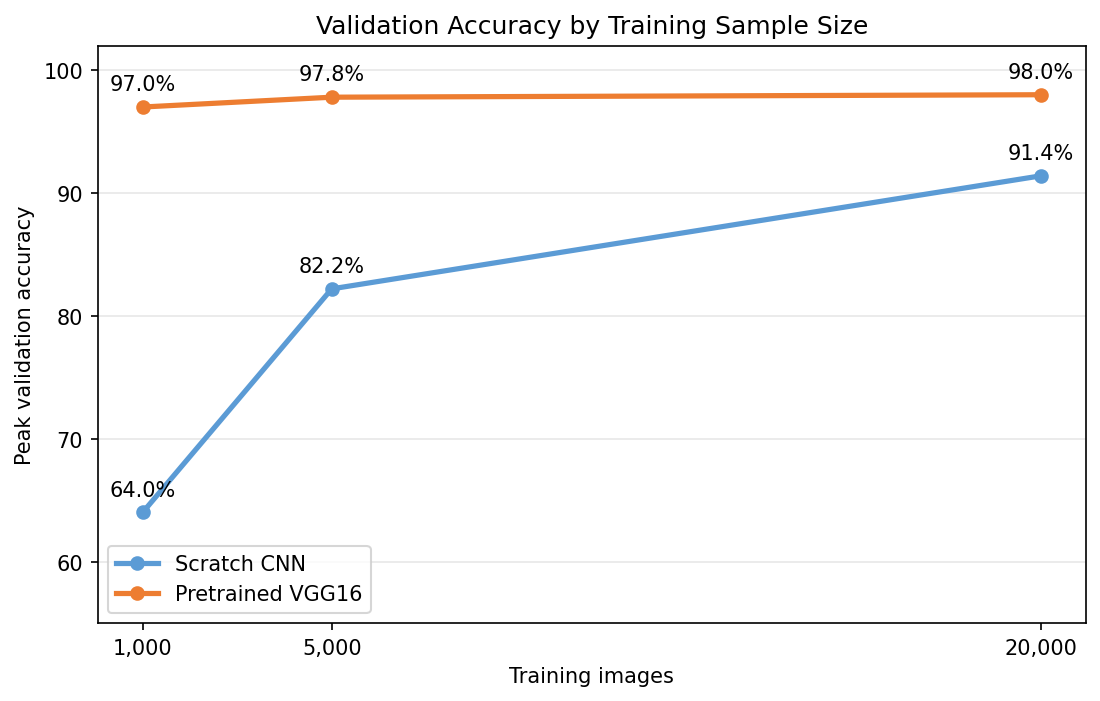

In [6]:
plot_data = results.sort_values("training_images")
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = {"Scratch CNN": "#5B9BD5", "Pretrained VGG16": "#ED7D31"}
for approach in ["Scratch CNN", "Pretrained VGG16"]:
    d = plot_data[plot_data["approach"] == approach]
    x = d["training_images"]
    y = d["peak_validation_accuracy"] * 100
    ax.plot(x, y, marker="o", linewidth=2.5, label=approach, color=colors[approach])
    for xi, yi in zip(x, y):
        ax.annotate(f"{yi:.1f}%", (xi, yi), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_title("Validation Accuracy by Training Sample Size")
ax.set_xlabel("Training images")
ax.set_ylabel("Peak validation accuracy")
ax.set_xticks([1000, 5000, 20000], ["1,000", "5,000", "20,000"])
ax.set_ylim(55, 102)
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", visible=False)
plt.show()

## 6. Conclusions

1. The scratch CNN was very sensitive to sample size. Its peak validation accuracy increased from 64.0% to 82.2% and then 91.4%.
2. VGG16 performed well even with 1,000 images because the frozen base already contained useful image features.
3. The 5,000-image VGG16 model had the highest test accuracy at 98.0%, while the 20,000-image model had the highest peak validation accuracy at 98.0%. The difference was small, so 5,000 images was the more efficient sample size for the frozen feature extractor.
4. For small or moderate image datasets, I would choose a pretrained network. Training from scratch becomes more reasonable when a much larger labeled sample is available.